In [1]:
### 07 – Defuzzification

In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# Define output universe

x = np.linspace(0, 10, 1000)

# First triangular membership function
def triangular(x, a, b, c):
    return np.maximum(
        np.minimum((x-a)/(b-a), (c-x)/(c-b)),
        0
    )

# Define two fuzzy membership functions

low = triangular(x, 0, 3, 6)

high = triangular(x, 4, 7, 10)

# Combine fuzzy outputs using maximum operation

aggregated = np.maximum(low, high)

print("Fuzzy membership functions created successfully.")

Fuzzy membership functions created successfully.


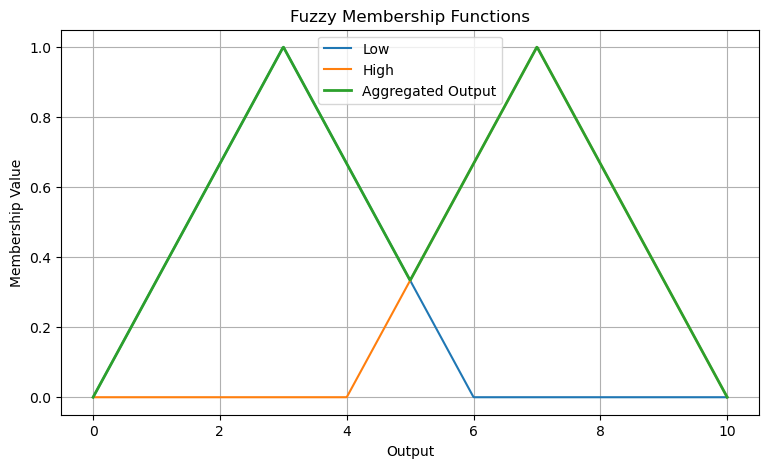

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(x, low, label="Low")
plt.plot(x, high, label="High")
plt.plot(x, aggregated, label="Aggregated Output", linewidth=2)

plt.xlabel("Output")
plt.ylabel("Membership Value")
plt.title("Fuzzy Membership Functions")

plt.legend()
plt.grid(True)
plt.show()

In [9]:
# Max Membership Method

max_membership = np.max(aggregated)

max_index = np.argmax(aggregated)

max_output = x[max_index]

print("Maximum Membership Value:", max_membership)

print("Defuzzified Output using Max Membership:", max_output)

Maximum Membership Value: 0.998998998998999
Defuzzified Output using Max Membership: 3.003003003003003


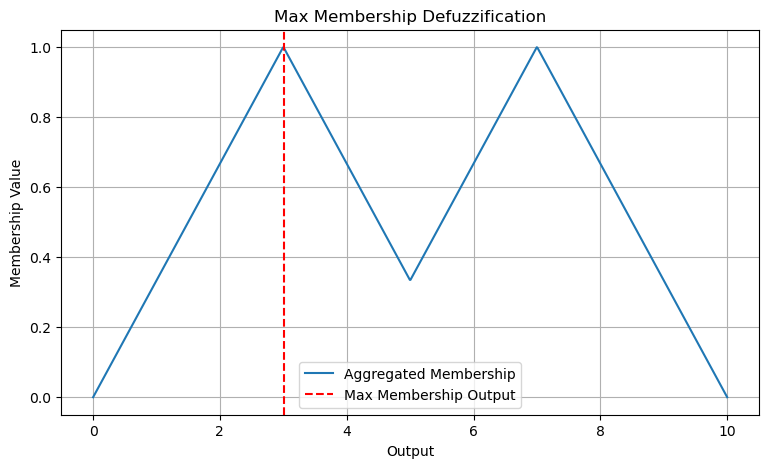

In [11]:
plt.figure(figsize=(9, 5))

plt.plot(x, aggregated, label="Aggregated Membership")

plt.axvline(
    max_output,
    color='red',
    linestyle='--',
    label="Max Membership Output"
)

plt.xlabel("Output")
plt.ylabel("Membership Value")
plt.title("Max Membership Defuzzification")

plt.legend()
plt.grid(True)
plt.show()

In [13]:
# Centroid Method

numerator = np.trapz(aggregated * x, x)

denominator = np.trapz(aggregated, x)

centroid = numerator / denominator

print("Defuzzified Output using Centroid Method:", centroid)

Defuzzified Output using Centroid Method: 4.999999999999999


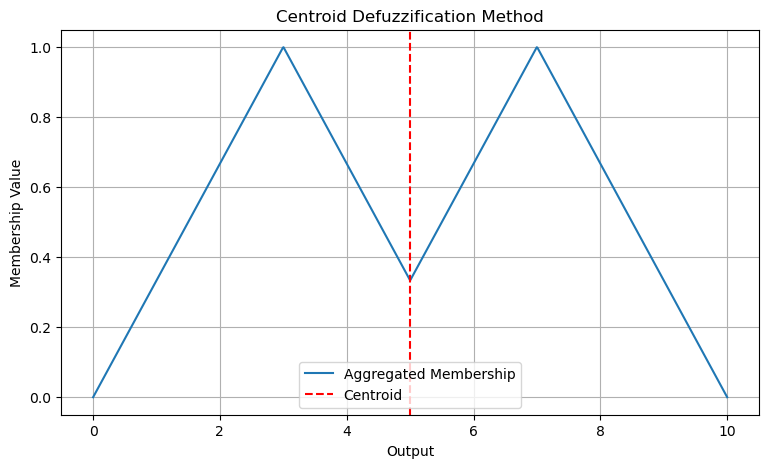

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(x, aggregated, label="Aggregated Membership")

plt.axvline(
    centroid,
    color='red',
    linestyle='--',
    label="Centroid"
)

plt.xlabel("Output")
plt.ylabel("Membership Value")
plt.title("Centroid Defuzzification Method")

plt.legend()
plt.grid(True)
plt.show()

In [17]:
# Weighted Average Method

# Representative centers of membership functions
centers = np.array([3, 7])

# Membership weights (firing strengths)
weights = np.array([0.5, 0.8])

# Calculate weighted average
weighted_average = np.sum(centers * weights) / np.sum(weights)

print("Weighted Average Output:", weighted_average)

Weighted Average Output: 5.461538461538462


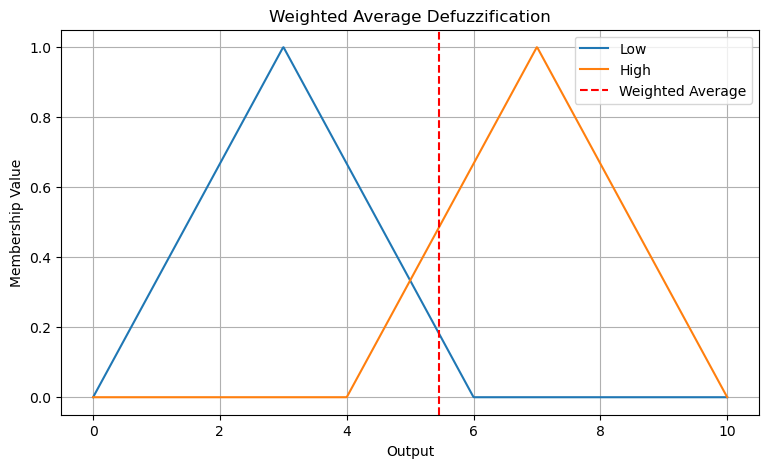

In [19]:
plt.figure(figsize=(9, 5))

plt.plot(x, low, label="Low")
plt.plot(x, high, label="High")

plt.axvline(
    weighted_average,
    color='red',
    linestyle='--',
    label="Weighted Average"
)

plt.xlabel("Output")
plt.ylabel("Membership Value")
plt.title("Weighted Average Defuzzification")

plt.legend()
plt.grid(True)
plt.show()

In [21]:
# Display comparison of all defuzzification methods

print("DEFUZZIFICATION RESULTS")
print("------------------------------")

print("Max Membership Method:", max_output)

print("Centroid Method:", centroid)

print("Weighted Average Method:", weighted_average)

DEFUZZIFICATION RESULTS
------------------------------
Max Membership Method: 3.003003003003003
Centroid Method: 4.999999999999999
Weighted Average Method: 5.461538461538462


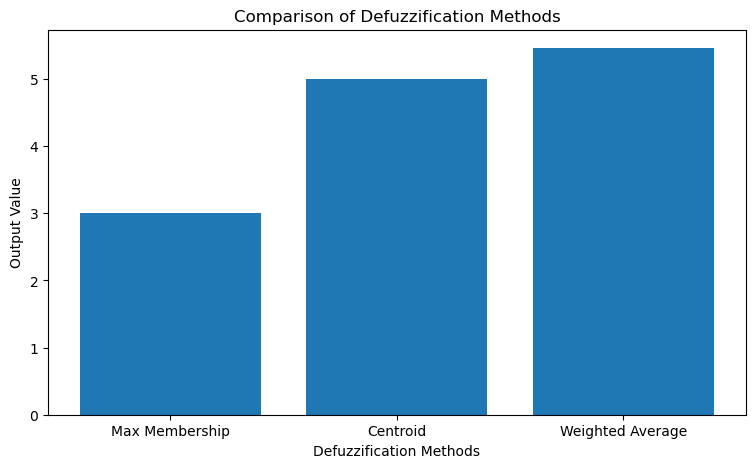

In [23]:
methods = [
    "Max Membership",
    "Centroid",
    "Weighted Average"
]

results = [
    max_output,
    centroid,
    weighted_average
]

plt.figure(figsize=(9, 5))

plt.bar(methods, results)

plt.xlabel("Defuzzification Methods")
plt.ylabel("Output Value")

plt.title("Comparison of Defuzzification Methods")

plt.show()